# 2. Data Review and Cleaning — RSQA Daily Air-Quality Dataset (2013–2025)

---

Student: Maria Jose Ospina

This notebook is the second stage of the project. It takes the daily dataset produced by
`01_build_daily_dataset.py` (`rsqa_daily_air_quality.csv`) and:

1. **Reviews** its structure, temporal and station coverage, and completeness.
2. **Verifies** that the aggregation and classification rules were applied correctly.
3. **Audits** physical plausibility and the choice of the daily statistic.
4. **Cleans** what is clearly invalid and **flags** what cannot be confirmed.
5. **Exports** an analysis-ready file (`rsqa_daily_clean.csv`) and a quality log.

The rationale for every decision is documented in `docs/data_preparation.md`.

**Guiding principle:** flag first, delete only with a physical justification. Every value removed is
recorded in the quality log so the process is reproducible.

## 2.1 Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# --- Paths -------------------------------------------------------------------
INPUT_PATH = Path("rsqa_daily_air_quality.csv")
OUTPUT_PATH = Path("rsqa_daily_clean.csv")
QUALITY_LOG_PATH = Path("rsqa_daily_quality_log.csv")

# --- Rules used by 01_build_daily_dataset.py (repeated here to verify them) -------
WHO_GUIDELINES = {"NO2": 25.0, "PM2.5": 15.0, "O3": 100.0}  # µg/m³
METRIC = {"NO2": "NO2_MEAN", "PM2.5": "PM25_MEAN", "O3": "O3_MDA8"}
HOURS = {"NO2": "NO2_N_HOURS", "PM2.5": "PM25_N_HOURS", "O3": "O3_N_HOURS"}
MIN_VALID_HOURS = 18
POLLUTANTS = list(METRIC)
DAY_TYPES = ["Bon", "Acceptable", "Mauvais"]

# --- Plot style: one fixed colour per pollutant and per day type ---------------
POLLUTANT_COLORS = {"NO2": "#2a78d6", "PM2.5": "#eb6834", "O3": "#1baf7a"}
DAYTYPE_COLORS = {"Bon": "#0ca30c", "Acceptable": "#fab219", "Mauvais": "#d03b3b"}
SEQ_BLUE = ListedColormap(["#f0efec", "#cde2fb", "#9ec5f4", "#6da7ec",
                           "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})

quality_log = []  # one dict per cleaning action


def log_action(step, rule, n_rows, action, detail=""):
    quality_log.append({"step": step, "rule": rule, "rows_affected": int(n_rows),
                        "action": action, "detail": detail})


def classify(frame):
    # Same rule as 01_build_daily_dataset.py: index = 100 x highest value/guideline ratio
    ratios = pd.DataFrame({p: frame[METRIC[p]] / WHO_GUIDELINES[p] for p in POLLUTANTS})
    max_ratio = ratios.max(axis=1, skipna=True)
    out = pd.DataFrame(index=frame.index)
    out["N_POLLUTANTS"] = ratios.notna().sum(axis=1)
    out["WHO_INDEX"] = (max_ratio * 100).round(2)
    out["DOMINANT"] = ratios.fillna(-np.inf).idxmax(axis=1).where(ratios.notna().any(axis=1))
    out["TIPO_DIA"] = np.select([max_ratio <= 1, max_ratio <= 2, max_ratio > 2],
                                DAY_TYPES, default=None)
    out["EXCEEDS_WHO"] = max_ratio > 1
    return out

## 2.2 Load the dataset

All columns are read with explicit types so nothing is inferred silently.

In [2]:
raw = pd.read_csv(
    INPUT_PATH,
    parse_dates=["DATE"],
    dtype={"NUMERO_STATION": "int64", "DOMINANT": "string", "TIPO_DIA": "string",
           "EXCEEDS_WHO": "bool"},
)
print(f"Rows: {len(raw):,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 32,567 | Columns: 22


,NUMERO_STATION,STATION_NAME,LATITUDE,LONGITUDE,ELEVATION_M,DATE,NO2_MEAN,PM25_MEAN,O3_MDA8,NO2_MEDIAN,PM25_MEDIAN,O3_MEAN,O3_MEDIAN,NO2_N_HOURS,PM25_N_HOURS,O3_N_HOURS,O3_N_8H_WINDOWS,N_POLLUTANTS,WHO_INDEX,DOMINANT,TIPO_DIA,EXCEEDS_WHO
0,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-01,11.3299,5.7542,55.5136,11.0305,4.95,50.5433,49.7119,24,24,24,19,3,55.51,O3,Bon,False
1,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-02,23.2360,6.2958,53.4448,20.9148,5.80,43.9438,44.9931,24,24,24,24,3,92.94,NO2,Bon,False
2,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-03,48.6229,11.5208,30.7804,47.9163,11.40,22.7795,24.2678,24,24,24,24,3,194.49,NO2,Acceptable,True
3,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-04,39.9496,15.9500,44.0559,31.3395,14.50,27.9225,36.9404,24,24,24,24,3,159.80,NO2,Acceptable,True
4,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-05,22.0037,7.0708,55.5316,13.7470,4.05,42.7658,50.2586,24,24,24,24,3,88.01,NO2,Bon,False


### Schema and key checks

In [3]:
EXPECTED_COLUMNS = [
    "NUMERO_STATION", "STATION_NAME", "LATITUDE", "LONGITUDE", "ELEVATION_M", "DATE",
    "NO2_MEAN", "PM25_MEAN", "O3_MDA8",
    "NO2_MEDIAN", "PM25_MEDIAN", "O3_MEAN", "O3_MEDIAN",
    "NO2_N_HOURS", "PM25_N_HOURS", "O3_N_HOURS", "O3_N_8H_WINDOWS",
    "N_POLLUTANTS", "WHO_INDEX", "DOMINANT", "TIPO_DIA", "EXCEEDS_WHO",
]
assert list(raw.columns) == EXPECTED_COLUMNS, f"Unexpected columns: {list(raw.columns)}"

df = raw.copy()
dup = df.duplicated(["NUMERO_STATION", "DATE"]).sum()
print("Duplicate station-day:", dup)
print("Date range           :", df["DATE"].min().date(), "->", df["DATE"].max().date())
print("Stations             :", df["NUMERO_STATION"].nunique())
print("Missing station data :", df[["STATION_NAME", "LATITUDE", "LONGITUDE"]].isna().sum().sum())
print("TIPO_DIA values      :", df["TIPO_DIA"].unique().tolist())
print("DOMINANT values      :", df["DOMINANT"].unique().tolist())
assert dup == 0
assert df["DATE"].notna().all()
assert df[["STATION_NAME", "LATITUDE", "LONGITUDE"]].notna().all().all()

Duplicate station-day: 0
Date range           : 2013-01-01 -> 2025-12-31
Stations             : 8
Missing station data : 0
TIPO_DIA values      : ['Bon', 'Acceptable', 'Mauvais']
DOMINANT values      : ['O3', 'NO2', 'PM2.5']


**Result.** The 22 expected columns are present, every date is valid, every station has its name and
coordinates, and `(NUMERO_STATION, DATE)` is unique: one row per station and day.

### Missing values

In [4]:
missing = df[list(METRIC.values())].isna().agg(["sum", "mean"]).T
missing.columns = ["missing_rows", "missing_%"]
missing["missing_%"] = (missing["missing_%"] * 100).round(2)
missing

,missing_rows,missing_%
NO2_MEAN,1678.0,5.15
PM25_MEAN,1327.0,4.07
O3_MDA8,1089.0,3.34


Missing values are **expected, not errors**. All eight stations measure the three pollutants, so a
missing value always means that the sensor **did not have enough valid data that day**: fewer than 18
valid hours, or, for `O3_MDA8`, fewer than 18 valid 8-hour windows (section 2.4). This happens during
maintenance, calibration or instrument failures, and affects only 3–5% of the station-days per pollutant.

A row is kept as long as at least one pollutant is valid. The missing values are **not imputed** here:
filling them is a modelling decision (for example, models that handle missing values natively, or
`N_POLLUTANTS == 3` when the full vector is needed).

## 2.3 Stations and coverage

The dataset only contains the stations with status **"ouvert"** in the official RSQA station list,
that is, the current permanent network (see `docs/data_preparation.md`, section 4).

The list and the project map have **nine** open stations, but the dataset has **eight**. Station
**33 (Autoroute 13)** has no measurements at all in the 2013–2025 hourly files (0 rows), so there is
nothing to aggregate for it. It is not replaced by the nearby closed station 66, because that would mix two
different sites into one series. It can be added when its data are published.

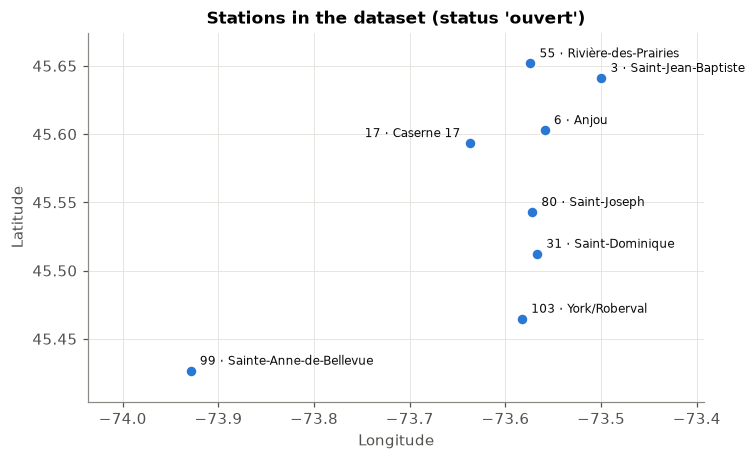

,NUMERO_STATION,STATION_NAME,LATITUDE,LONGITUDE,ELEVATION_M
0,3,Saint-Jean-Baptiste,45.6410,-73.4997,19.0
1,6,Anjou,45.6028,-73.5589,51.0
2,17,Caserne 17,45.5933,-73.6373,41.0
3,31,Saint-Dominique,45.5122,-73.5668,32.0
4,55,Rivière-des-Prairies,45.6517,-73.5739,29.0
5,80,Saint-Joseph,45.5428,-73.5720,53.0
6,99,Sainte-Anne-de-Bellevue,45.4265,-73.9289,39.0
7,103,York/Roberval,45.4646,-73.5826,25.0


In [5]:
stations = (df.groupby(["NUMERO_STATION", "STATION_NAME"])
              .agg(LATITUDE=("LATITUDE", "first"), LONGITUDE=("LONGITUDE", "first"),
                   ELEVATION_M=("ELEVATION_M", "first"))
              .reset_index())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(stations["LONGITUDE"], stations["LATITUDE"], s=60, color="#2a78d6",
           edgecolor="white", linewidth=1.5, zorder=3)
LEFT_LABELS = {17}  # labels placed to the left to avoid overlapping a neighbour
for _, r in stations.iterrows():
    left = r.NUMERO_STATION in LEFT_LABELS
    ax.annotate(f"{r.NUMERO_STATION} · {r.STATION_NAME}", (r.LONGITUDE, r.LATITUDE),
                xytext=(-6 if left else 6, 4), textcoords="offset points",
                ha="right" if left else "left", fontsize=8, color="#0b0b0b")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Stations in the dataset (status 'ouvert')")
ax.set_aspect(1 / np.cos(np.deg2rad(45.5)))  # approximate distance-preserving aspect at Montréal
ax.margins(x=0.25, y=0.1)
plt.tight_layout()
plt.show()

stations

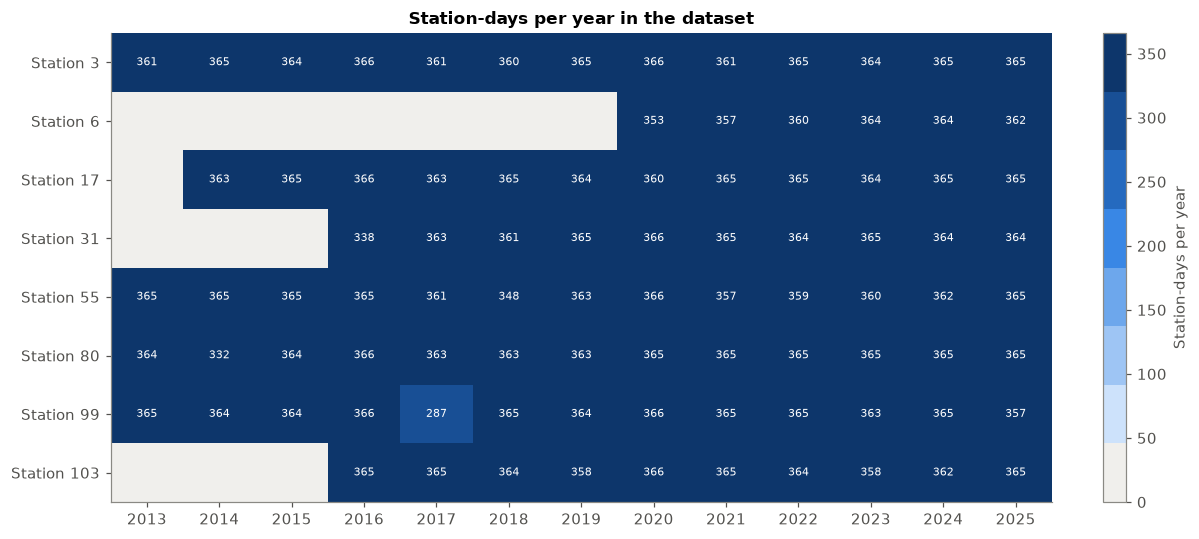

In [6]:
df["YEAR"] = df["DATE"].dt.year
df["MONTH"] = df["DATE"].dt.month

coverage = df.pivot_table(index="NUMERO_STATION", columns="YEAR",
                          values="DATE", aggfunc="count").fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(coverage.values, aspect="auto", cmap=SEQ_BLUE, vmin=0, vmax=366)
ax.set_xticks(range(coverage.shape[1]), coverage.columns)
ax.set_yticks(range(coverage.shape[0]), [f"Station {s}" for s in coverage.index])
ax.grid(False)
for i in range(coverage.shape[0]):
    for j in range(coverage.shape[1]):
        v = coverage.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=7,
                    color="white" if v > 250 else "#0b0b0b")
cbar = fig.colorbar(im, ax=ax, fraction=0.025)
cbar.set_label("Station-days per year")
ax.set_title("Station-days per year in the dataset")
plt.tight_layout()
plt.show()

In [7]:
station_summary = df.groupby("NUMERO_STATION").agg(
    first_year=("YEAR", "min"),
    last_year=("YEAR", "max"),
    days=("DATE", "count"),
    NO2_days=("NO2_MEAN", "count"),
    PM25_days=("PM25_MEAN", "count"),
    O3_days=("O3_MDA8", "count"),
)
station_summary["pollutants_measured"] = (
    station_summary[["NO2_days", "PM25_days", "O3_days"]].gt(0).sum(axis=1)
)
station_summary

,first_year,last_year,days,NO2_days,PM25_days,O3_days,pollutants_measured
NUMERO_STATION,,,,,,,
3,2013,2025,4728,4486,4666,4513,3
6,2020,2025,2160,1995,2127,2097,3
17,2014,2025,4370,4159,4226,4290,3
31,2016,2025,3615,3471,3578,3513,3
55,2013,2025,4701,4612,4603,4634,3
80,2013,2025,4705,4090,4594,4479,3
99,2013,2025,4656,4512,4059,4424,3
103,2016,2025,3632,3564,3387,3528,3


**Observations**

* All eight stations measure the **three pollutants**, so missing values come from sensor downtime, not
  from missing instruments.
* The panel is **not fully balanced**: four stations cover 2013–2025 (3, 55, 80, 99), station 17 starts
  in 2014, 31 and 103 in 2016, and 6 (Anjou) in 2020. Comparisons across years should take this into account, for
  example by using only the stations present in both periods being compared.
* Station 33 (Autoroute 13) is open but has no data in 2013–2025, so its sector has no observations;
  the heatmap should show it as "no data" rather than interpolate it.

## 2.4 Completeness rules

`01_build_daily_dataset.py` keeps a daily value only when the pollutant has **at least 18 valid hours**
(75% of the day). For O3, the daily maximum 8-hour mean (`O3_MDA8`) additionally needs at least 18 valid
8-hour windows. This section checks that the rule was applied in every row.

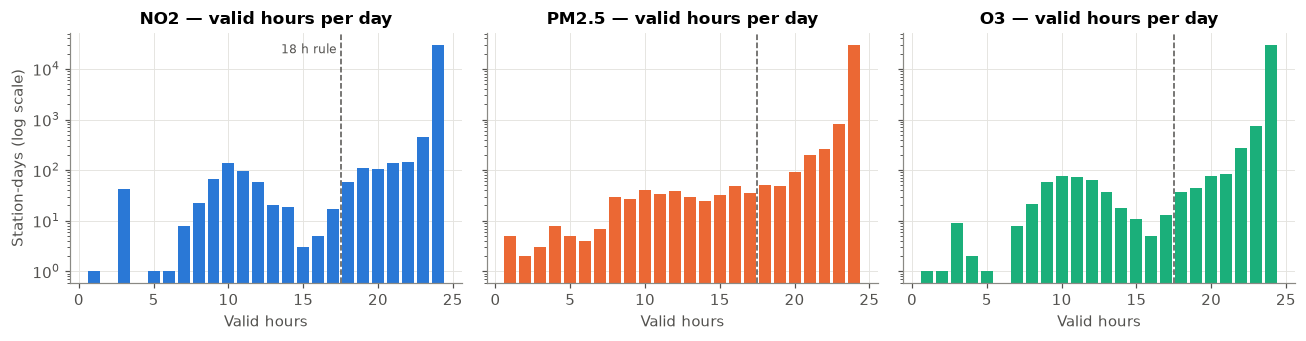

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, p in zip(axes, POLLUTANTS):
    h = df[HOURS[p]]
    h = h[h > 0]  # 0 = station does not measure this pollutant that day
    counts = h.value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=POLLUTANT_COLORS[p], width=0.8)
    ax.axvline(MIN_VALID_HOURS - 0.5, color="#52514e", linestyle="--", linewidth=1)
    ax.set_yscale("log")
    ax.set_title(f"{p} — valid hours per day")
    ax.set_xlabel("Valid hours")
axes[0].set_ylabel("Station-days (log scale)")
axes[0].text(MIN_VALID_HOURS - 0.8, axes[0].get_ylim()[1] * 0.4, "18 h rule",
             ha="right", fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()

In [9]:
checks = {}
for p in ["NO2", "PM2.5"]:
    valid_value = df[METRIC[p]].notna()
    enough_hours = df[HOURS[p]] >= MIN_VALID_HOURS
    checks[p] = int((valid_value != enough_hours).sum())

o3_value = df["O3_MDA8"].notna()
o3_rule = (df["O3_N_HOURS"] >= MIN_VALID_HOURS) & (df["O3_N_8H_WINDOWS"] >= MIN_VALID_HOURS)
checks["O3"] = int((o3_value != o3_rule).sum())
print("Rows that break the completeness rule:", checks)
assert sum(checks.values()) == 0
assert df[list(HOURS.values())].le(24).all().all()

o3_window_only = ((df["O3_N_HOURS"] >= 18) & (df["O3_N_8H_WINDOWS"] < 18)).sum()
print(f"Days with >= 18 O3 hours but < 18 valid 8-h windows: {o3_window_only}")
print(f"Share of kept values with all 24 hours: "
      + ", ".join(f"{p} {(df.loc[df[METRIC[p]].notna(), HOURS[p]] == 24).mean():.1%}" for p in POLLUTANTS))

Rows that break the completeness rule: {'NO2': 0, 'PM2.5': 0, 'O3': 0}
Days with >= 18 O3 hours but < 18 valid 8-h windows: 142
Share of kept values with all 24 hours: NO2 96.7%, PM2.5 95.3%, O3 96.5%


**Result.** The completeness rule holds in every row and no day has more than 24 hours. Most kept values
are based on the full 24 hours, so the 18-hour floor removes little. A small number of days have 18 or
more O3 hours but fewer than 18 valid 8-hour windows (the missing hours are spread out); `O3_MDA8` is
empty on those days, as intended.

## 2.5 Verification of the classification

The index, dominant pollutant and day type are recomputed from `NO2_MEAN`, `PM25_MEAN` and `O3_MDA8`
with the WHO 2021 guidelines, and compared with the values written by the build script.

| Pollutant | Daily metric | WHO 2021 guideline |
|---|---|---|
| NO2 | 24-hour mean | 25 µg/m³ |
| PM2.5 | 24-hour mean | 15 µg/m³ |
| O3 | Daily maximum 8-hour mean | 100 µg/m³ |

In [10]:
check = classify(df)
mismatch = {
    "WHO_INDEX": int((check["WHO_INDEX"] - df["WHO_INDEX"]).abs().gt(0.011).sum()),  # 0.01 = rounding
    "DOMINANT": int((check["DOMINANT"] != df["DOMINANT"]).sum()),
    "TIPO_DIA": int((check["TIPO_DIA"] != df["TIPO_DIA"]).sum()),
    "EXCEEDS_WHO": int((check["EXCEEDS_WHO"] != df["EXCEEDS_WHO"]).sum()),
    "N_POLLUTANTS": int((check["N_POLLUTANTS"] != df["N_POLLUTANTS"]).sum()),
}
print("Mismatches:", mismatch)
assert sum(mismatch.values()) == 0

Mismatches: {'WHO_INDEX': 0, 'DOMINANT': 0, 'TIPO_DIA': 0, 'EXCEEDS_WHO': 0, 'N_POLLUTANTS': 0}


**Result.** The classification in the file matches the rule exactly.

## 2.6 Physical plausibility

Four checks, from strict to soft:

1. **Hard limits** — no negative concentrations.
2. **Seasonal sanity check** — monthly profiles must follow known behaviour: O3 is formed by sunlight, so
   it peaks in spring and summer; NO2 peaks in winter (heating, shallow mixing layer). This also confirms
   that day and month were not swapped when dates were parsed.
3. **Flatline values** — a whole day of exactly 0 is a stuck sensor, not a measurement.
4. **Spatial consistency** — a daily value is an *isolated spike* when it is above the 99th percentile of
   that pollutant **and** more than 3 times the network median for the same day (days with at least 3
   reporting stations).

The IQR rule is not used to delete data: pollutant distributions are right-skewed, so IQR would mark
thousands of real high-pollution days as outliers, and those are exactly the days the model must learn.

In [11]:
negatives = (df[list(METRIC.values()) + ["NO2_MEDIAN", "PM25_MEDIAN", "O3_MEAN", "O3_MEDIAN"]] < 0).sum()
print("Negative values:", int(negatives.sum()))
assert negatives.sum() == 0

Negative values: 0


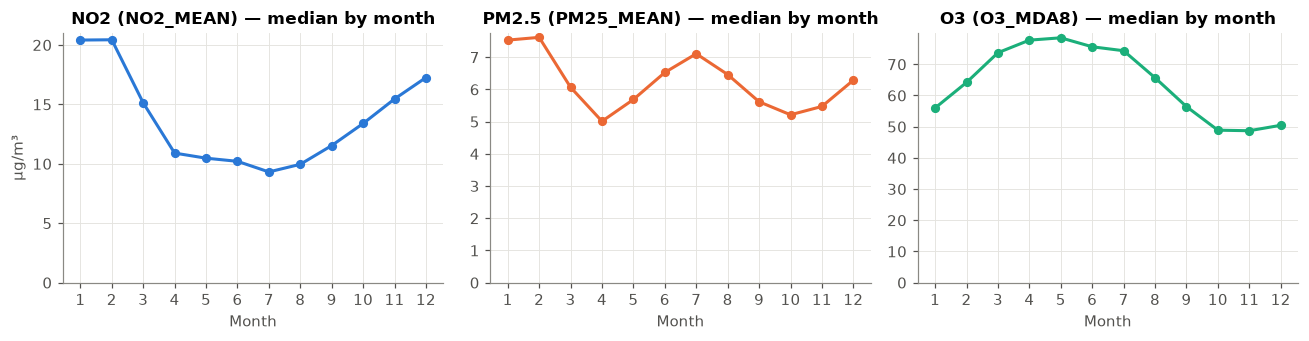

In [12]:
monthly = df.groupby("MONTH")[list(METRIC.values())].median()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
for ax, p in zip(axes, POLLUTANTS):
    ax.plot(monthly.index, monthly[METRIC[p]], color=POLLUTANT_COLORS[p],
            linewidth=2, marker="o", markersize=5)
    ax.set_title(f"{p} ({METRIC[p]}) — median by month")
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Month")
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("µg/m³")
plt.tight_layout()
plt.show()

The profiles match the expected seasonality (O3 highest in April–July, NO2 highest in December–February),
so the date parsing and the units are consistent.

### Flatline values (stuck sensor)

In [13]:
flatline = (df["NO2_MEAN"] == 0) & (df["NO2_N_HOURS"] >= MIN_VALID_HOURS)
df.loc[flatline, ["NUMERO_STATION", "DATE", "NO2_MEAN", "NO2_MEDIAN", "NO2_N_HOURS", "PM25_MEAN", "O3_MDA8"]]

,NUMERO_STATION,DATE,NO2_MEAN,NO2_MEDIAN,NO2_N_HOURS,PM25_MEAN,O3_MDA8
16061,55,2016-04-03,0.0,0.0,24,3.8728,75.4104
24768,99,2014-05-05,0.0,0.0,24,0.7000,60.6503
25120,99,2015-04-24,0.0,0.0,24,1.4542,52.8459
27211,99,2021-04-02,0.0,0.0,24,3.6657,84.3553
27214,99,2021-04-05,0.0,0.0,24,6.1991,94.6081
27883,99,2023-02-03,0.0,0.0,24,2.1418,79.7152


On these days NO2 reads exactly **0 for every hour**, while PM2.5 and O3 at the same station look normal.
Real urban NO2 never stays at exactly zero for 24 hours; the instrument was stuck at its lower limit.
The NO2 value is set to `NaN` (mean and median), and the day is reclassified with the remaining pollutants
(section 2.8).

In [14]:
df.loc[flatline, ["NO2_MEAN", "NO2_MEDIAN"]] = np.nan
log_action("2.6", "NO2 = 0 for all valid hours (stuck sensor)", flatline.sum(),
           "NO2_MEAN / NO2_MEDIAN set to NaN",
           "; ".join(f"st {s} {d:%Y-%m-%d}" for s, d in df.loc[flatline, ["NUMERO_STATION", "DATE"]].values))

### Isolated spikes

In [15]:
spike = {}
for p in POLLUTANTS:
    col = METRIC[p]
    by_day = df.groupby("DATE")[col]
    network_median = by_day.transform("median")
    n_reporting = by_day.transform("count")
    spike[p] = (n_reporting >= 3) & (df[col] > df[col].quantile(0.99)) & (df[col] > 3 * network_median)
    df[f"_{p}_network_median"] = network_median

isolated = pd.concat(
    [df.loc[spike[p], ["NUMERO_STATION", "DATE", METRIC[p], f"_{p}_network_median"]]
       .rename(columns={METRIC[p]: "value", f"_{p}_network_median": "network_median"})
       .assign(pollutant=p)
     for p in POLLUTANTS]
)
isolated["ratio_to_network"] = (isolated["value"] / isolated["network_median"]).round(1)
df = df.drop(columns=[c for c in df.columns if c.startswith("_")])
isolated.round({"value": 2, "network_median": 2})

,NUMERO_STATION,DATE,value,network_median,pollutant,ratio_to_network
11557,31,2016-11-23,32.87,3.75,PM2.5,8.8
13924,31,2023-05-25,57.72,4.23,PM2.5,13.6
13925,31,2023-05-26,67.11,7.46,PM2.5,9.0
21563,80,2018-07-21,27.27,8.51,PM2.5,3.2
21707,80,2018-12-13,87.45,15.82,PM2.5,5.5
29102,103,2016-06-17,30.97,9.13,PM2.5,3.4
32268,103,2025-03-08,42.89,2.67,PM2.5,16.1


**No isolated spikes for NO2 or O3.** O3 is a regional pollutant, so any station far above the rest
would be suspicious; none is.

**Seven PM2.5 station-days are isolated spikes.** PM2.5 has local sources (traffic, wood burning,
construction, fires, fireworks), so a peak at a single station is physically possible. These values
cannot be confirmed or rejected from daily data, so they are **kept and flagged** with
`FLAG_PM25_LOCAL_SPIKE`. Because the daily metric is the mean, a few very high hours can lift a whole day;
the flag lets the modelling stage test the effect of excluding them.

In [16]:
df["FLAG_PM25_LOCAL_SPIKE"] = spike["PM2.5"]
log_action("2.6", "Isolated PM2.5 spike (> p99 and > 3x network median)", spike["PM2.5"].sum(),
           "kept + FLAG_PM25_LOCAL_SPIKE",
           "; ".join(f"st {s} {d:%Y-%m-%d}" for s, d in df.loc[spike["PM2.5"], ["NUMERO_STATION", "DATE"]].values))

### Network-wide extreme events (kept)

In [17]:
(df.groupby("DATE")["PM25_MEAN"].median().nlargest(6)
   .rename("network_median_PM25_MEAN").round(1).to_frame())

,network_median_PM25_MEAN
DATE,
2023-06-25,125.9
2025-07-26,76.6
2025-06-06,68.9
2013-07-02,53.0
2015-01-15,49.7
2025-06-07,49.0


The highest PM2.5 days affect the whole network, for example **25 June 2023**, when wildfire smoke covered
Montréal. They are real events and are kept: removing them would erase the "Mauvais" class the model is
supposed to predict.

## 2.7 Why the 24-hour mean and not the median

The first version of the pipeline used the daily **median** because it is robust to short peaks. The
WHO guidelines, however, are defined on the **24-hour mean** (NO2, PM2.5) and on the **daily maximum
8-hour mean** (O3). For right-skewed pollution data the median is usually lower than the mean, so a
median-based classification misses exceedances. The comparison below quantifies that difference, using
the medians kept in the file.

In [18]:
median_version = pd.DataFrame({
    "NO2_MEAN": df["NO2_MEDIAN"], "PM25_MEAN": df["PM25_MEDIAN"], "O3_MDA8": df["O3_MEDIAN"],
})
median_class = classify(median_version)["TIPO_DIA"]
comparison = pd.crosstab(df["TIPO_DIA"], median_class,
                         rownames=["Guideline metric (mean / MDA8)"], colnames=["All medians"])
comparison.reindex(index=DAY_TYPES, columns=DAY_TYPES)

All medians,Bon,Acceptable,Mauvais
Guideline metric (mean / MDA8),,,
Bon,26044,176,0
Acceptable,1964,3896,76
Mauvais,7,66,338


In [19]:
diff = (df[["NO2_MEAN", "PM25_MEAN"]].values - df[["NO2_MEDIAN", "PM25_MEDIAN"]].values)
print(f"Mean - median, NO2  : {np.nanmean(diff[:, 0]):.2f} µg/m³ on average")
print(f"Mean - median, PM2.5: {np.nanmean(diff[:, 1]):.2f} µg/m³ on average")
print(f"O3_MDA8 - O3_MEDIAN : {(df['O3_MDA8'] - df['O3_MEDIAN']).mean():.2f} µg/m³ on average")

Mean - median, NO2  : 1.68 µg/m³ on average
Mean - median, PM2.5: 0.53 µg/m³ on average
O3_MDA8 - O3_MEDIAN : 14.92 µg/m³ on average


Classifying with medians would label 1,971 of the 6,347 days that exceed a guideline (about 31%) as
"Bon", most of them because the O3 median is much lower than the 8-hour maximum the WHO guideline refers to.
The guideline metrics are therefore used for `TIPO_DIA`, and the medians stay in the dataset as robust
additional features for the model.

## 2.8 Re-classification after cleaning

The NO2 values removed in 2.6 change `N_POLLUTANTS` on those days, so the classification columns are
recomputed with the same rule.

In [20]:
before = df["TIPO_DIA"].copy()
new = classify(df)
df[new.columns] = new
changed = int((before != df["TIPO_DIA"]).sum())
log_action("2.8", "Classification recomputed after cleaning", changed,
           "N_POLLUTANTS / WHO_INDEX / DOMINANT / TIPO_DIA / EXCEEDS_WHO updated")
print("Day types changed by the cleaning:", changed)

Day types changed by the cleaning: 0


### Class balance

In [21]:
balance = pd.DataFrame({
    "station_days": df["TIPO_DIA"].value_counts().reindex(DAY_TYPES),
    "share_%": (df["TIPO_DIA"].value_counts(normalize=True).reindex(DAY_TYPES) * 100).round(1),
})
balance

,station_days,share_%
TIPO_DIA,,
Bon,26220,80.5
Acceptable,5936,18.2
Mauvais,411,1.3


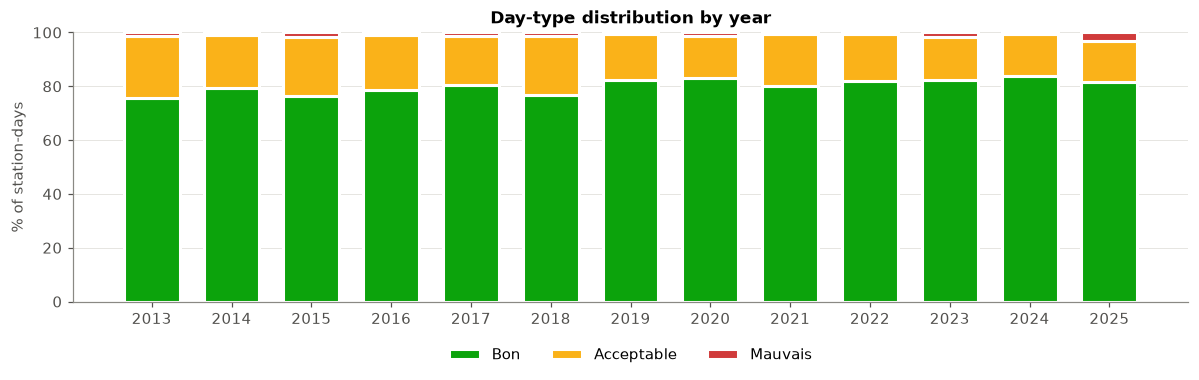

In [22]:
by_year = pd.crosstab(df["YEAR"], df["TIPO_DIA"], normalize="index").reindex(columns=DAY_TYPES) * 100

fig, ax = plt.subplots(figsize=(11, 3.6))
bottom = np.zeros(len(by_year))
for cls in DAY_TYPES:
    ax.bar(by_year.index.astype(str), by_year[cls], bottom=bottom, color=DAYTYPE_COLORS[cls],
           edgecolor="white", linewidth=2, width=0.7, label=cls)
    bottom += by_year[cls].values
ax.set_ylim(0, 100)
ax.set_ylabel("% of station-days")
ax.set_title("Day-type distribution by year")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

In [23]:
dominant = pd.crosstab(df["DOMINANT"], df["TIPO_DIA"]).reindex(columns=DAY_TYPES)
dominant["total"] = dominant.sum(axis=1)
dominant

TIPO_DIA,Bon,Acceptable,Mauvais,total
DOMINANT,,,,
NO2,6745,3766,219,10730
O3,17399,1041,0,18440
PM2.5,2076,1129,192,3397


**Observations**

* The classes are imbalanced (most days are "Bon" and "Mauvais" is rare). The model will need metrics
  that handle imbalance (F1-macro, PR-AUC) rather than accuracy.
* The share of "Bon" days moves from about 76–80% in 2013–2018 to about 80–84% from 2019 onwards.
* "Mauvais" days are most frequent in 2025 and 2023, the years with the network-wide PM2.5 episodes
  listed in 2.6.
* O3 decides the most days, but none of them is "Mauvais" (O3_MDA8 never reaches twice its guideline).
  NO2 and PM2.5 share the "Mauvais" days almost equally.

## 2.9 Pollutants available per row

`N_POLLUTANTS` records how many of the three pollutants were used to classify each day. Since every
station measures the three pollutants, a value below 3 means that one or two sensors did not have enough
valid data that day. Those days are classified only with the pollutants available, so a "Bon" day with
`N_POLLUTANTS < 3` is less certain: an exceedance of the missing pollutant would not be seen.

In [24]:
pd.crosstab(df["N_POLLUTANTS"], df["TIPO_DIA"], margins=True).reindex(columns=DAY_TYPES + ["All"])

TIPO_DIA,Bon,Acceptable,Mauvais,All
N_POLLUTANTS,,,,
1,407,22,2,431
2,2684,506,48,3238
3,23129,5408,361,28898
All,26220,5936,411,32567


## 2.10 Final checks and export

In [25]:
OUTPUT_COLUMNS = [
    "NUMERO_STATION", "STATION_NAME", "LATITUDE", "LONGITUDE", "ELEVATION_M",
    "DATE", "YEAR", "MONTH",
    "NO2_MEAN", "PM25_MEAN", "O3_MDA8",
    "NO2_MEDIAN", "PM25_MEDIAN", "O3_MEAN", "O3_MEDIAN",
    "NO2_N_HOURS", "PM25_N_HOURS", "O3_N_HOURS", "O3_N_8H_WINDOWS",
    "N_POLLUTANTS", "WHO_INDEX", "DOMINANT", "TIPO_DIA", "EXCEEDS_WHO",
    "FLAG_PM25_LOCAL_SPIKE",
]
clean = df[OUTPUT_COLUMNS].sort_values(["NUMERO_STATION", "DATE"]).reset_index(drop=True)

assert not clean.duplicated(["NUMERO_STATION", "DATE"]).any()
assert clean["TIPO_DIA"].isin(DAY_TYPES).all()
assert clean["N_POLLUTANTS"].between(1, 3).all()
assert (clean[["NO2_MEAN", "PM25_MEAN", "O3_MDA8"]].dropna() > 0).all().all()

clean.to_csv(OUTPUT_PATH, index=False, float_format="%.4f", date_format="%Y-%m-%d")
log_df = pd.DataFrame(quality_log)
log_df.to_csv(QUALITY_LOG_PATH, index=False)

print(f"Input rows : {len(raw):,}")
print(f"Output rows: {len(clean):,}")
print(f"Saved      : {OUTPUT_PATH} and {QUALITY_LOG_PATH}")
log_df

Input rows : 32,567
Output rows: 32,567
Saved      : rsqa_daily_clean.csv and rsqa_daily_quality_log.csv


,step,rule,rows_affected,action,detail
0,2.6,NO2 = 0 for all valid hours (stuck sensor),6,NO2_MEAN / NO2_MEDIAN set to NaN,st 55 2016-04-03; st 99 2014-05-05; st 99 2015...
1,2.6,Isolated PM2.5 spike (> p99 and > 3x network m...,7,kept + FLAG_PM25_LOCAL_SPIKE,st 31 2016-11-23; st 31 2023-05-25; st 31 2023...
2,2.8,Classification recomputed after cleaning,0,N_POLLUTANTS / WHO_INDEX / DOMINANT / TIPO_DIA...,


In [26]:
clean.head()

,NUMERO_STATION,STATION_NAME,LATITUDE,LONGITUDE,ELEVATION_M,DATE,YEAR,MONTH,NO2_MEAN,PM25_MEAN,O3_MDA8,NO2_MEDIAN,PM25_MEDIAN,O3_MEAN,O3_MEDIAN,NO2_N_HOURS,PM25_N_HOURS,O3_N_HOURS,O3_N_8H_WINDOWS,N_POLLUTANTS,WHO_INDEX,DOMINANT,TIPO_DIA,EXCEEDS_WHO,FLAG_PM25_LOCAL_SPIKE
0,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-01,2013,1,11.3299,5.7542,55.5136,11.0305,4.95,50.5433,49.7119,24,24,24,19,3,55.51,O3,Bon,False,False
1,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-02,2013,1,23.2360,6.2958,53.4448,20.9148,5.80,43.9438,44.9931,24,24,24,24,3,92.94,NO2,Bon,False,False
2,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-03,2013,1,48.6229,11.5208,30.7804,47.9163,11.40,22.7795,24.2678,24,24,24,24,3,194.49,NO2,Acceptable,True,False
3,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-04,2013,1,39.9496,15.9500,44.0559,31.3395,14.50,27.9225,36.9404,24,24,24,24,3,159.80,NO2,Acceptable,True,False
4,3,Saint-Jean-Baptiste,45.641,-73.4997,19.0,2013-01-05,2013,1,22.0037,7.0708,55.5316,13.7470,4.05,42.7658,50.2586,24,24,24,24,3,88.01,NO2,Bon,False,False


## 2.11 Summary

| Check | Result |
|---|---|
| Schema, dates and unique station-day key | Passed |
| 18-hour completeness rule per pollutant (and 18 windows for O3) | Passed in every row |
| Classification matches the WHO 2021 rule | Passed in every row |
| Negative values | None |
| Seasonal profiles (O3 summer, NO2 winter) | As expected |
| NO2 stuck at 0 for a whole day | 6 station-days → NO2 set to `NaN` (day type unchanged) |
| Isolated PM2.5 spikes | 7 station-days → kept and flagged |
| Network-wide extreme days (e.g. wildfire smoke) | Kept |
| Missing pollutants | Not imputed; `N_POLLUTANTS` records availability |

**Using `rsqa_daily_clean.csv` in the next stages**

* **Classification target:** `TIPO_DIA` (3 classes) or `EXCEEDS_WHO` (binary).
* **Avoid leakage:** `WHO_INDEX`, `DOMINANT`, `TIPO_DIA` and `EXCEEDS_WHO` are computed from the
  pollutant columns. If the model predicts the day type from atmospheric variables, the pollutant
  columns of the **same day** must not be used as inputs.
* **Subset by model:** all rows for models that accept missing values; `N_POLLUTANTS == 3` when the
  full vector is needed. Optionally exclude `FLAG_PM25_LOCAL_SPIKE` rows as a sensitivity test.
* **Validation:** split by time (earlier years for training, later years for testing), not at random,
  because consecutive days are strongly correlated.